# Baselines for single-turbine gap filling

A turbine stops reporting. Its last reading was `s` steps ago. We reconstruct its active
power `Patv` at the current step from whatever is still available. `s` is the only knob:

| `s` | gap | what is still useful |
|---|---|---|
| 1 | 10 min | the turbine's own last reading is 10 minutes old; persistence is strong |
| 6 | 1 h | own history decaying, neighbours becoming competitive |
| 36 | 6 h | own history nearly worthless; only the rest of the farm can help |

Sweeping `s` therefore covers the whole range between imputation (`s = 1`) and
forecasting (`s = 36`) without having to choose between the two framings.

**Protocol.** Every model below is fitted and scored under identical conditions:

- **Masked turbine.** One turbine per episode. All of its channels are hidden from
  `t - s + 1` onwards; it may only be read at steps `<= t - s`.
- **Everything else is visible.** The other 133 turbines report normally at step `t`.
- **Scored cells.** A cell counts only if the true record is `target_valid` *and* the
  turbine's last pre-gap reading exists, so persistence and the history models are
  defined. All models see the same episode set, so the columns are comparable row to row.
- **Splits.** Day-based, from `config.py`: train 1-171, val 172-196, test 197-245.
  Episodes are drawn inside a split and the history window may not cross its start.
- **Metric.** MAE and RMSE in kW. Rated power is 1500 kW.
- **Reference.** Persistence over the whole dataset (`results/tables/stage_a_persistence.csv`)
  is 77.66 / 173.31 / 334.91 kW MAE at 10 min / 1 h / 6 h.

**No leakage.** Any farm-level aggregate is computed from reporting turbines *excluding*
the masked one. A plain farm mean would feed the answer back in at about 1/134 weight.


In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from windgnn import config as C
from windgnn import data as D
from windgnn import baselines as B

C.set_plot_style()
pd.set_option("display.width", 200)
print("repo root :", ROOT)
print("data root :", C.DATA_ROOT)


repo root : C:\Users\franc\Desktop\complexity\GraphMLAssignment
data root : C:\Users\franc\Desktop\complexity\GraphMLAssignment\SDWPF_dataset


In [2]:
t0 = time.time()
df = D.load_analysis_table()
ctx = B.build_context(df)
print(f"analysis table : {df.shape[0]:,} rows in {time.time()-t0:.1f}s")
print(f"power matrix   : {ctx.power.shape[0]:,} steps x {ctx.power.shape[1]} turbines")
print(f"reporting      : {np.isfinite(ctx.power).mean()*100:.2f}%")
print(f"target_valid   : {ctx.valid.mean()*100:.2f}%   (stage A: 76.06%)")
print(f"climatology    : {ctx.clim.min():.1f} .. {ctx.clim.max():.1f} kW per turbine/time-of-day")


analysis table : 4,727,520 rows in 4.3s
power matrix   : 35,280 steps x 134 turbines
reporting      : 98.95%
target_valid   : 76.06%   (stage A: 76.06%)
climatology    : 215.9 .. 678.0 kW per turbine/time-of-day


### Episode counts

The power matrix is reindexed onto the full `0 .. 35279` step grid before anything else.
`pivot_table` silently drops the 264 steps where no turbine reported at all, and without
the reindex a lag of `s` steps would jump across the 37.8-hour farm-wide blackout as
though the two sides were adjacent.


In [3]:
rng = np.random.default_rng(B.RNG_SEED)
rows = []
for s in (1, 6, 36):
    for split in ("train", "val", "test"):
        ep = B.sample_episodes(ctx, split, s, None, 12, rng)
        rows.append({"silence": s, "split": split, "episodes": len(ep),
                     "turbines": int(np.unique(ep.turb).size),
                     "mean target [kW]": float(ep.truth(ctx).mean())})
pd.DataFrame(rows)


,silence,split,episodes,turbines,mean target [kW]
0,1,train,2542450,134,464.305023
1,1,val,347990,134,411.957397
2,1,test,694230,134,449.809753
3,6,train,2540388,134,464.193665
4,6,val,347371,134,412.348633
5,6,test,693435,134,449.872284
6,36,train,2531970,134,463.875366
7,36,val,343256,134,415.348694
8,36,test,688936,134,449.646515


## Models

| model | inputs | what it isolates |
|---|---|---|
| `climatology` | turbine id, time of day | the do-nothing floor: no knowledge of the moment |
| `persistence` | the turbine's last reading | pure temporal carry-over |
| `linear-own` | ridge on 12 of its own past readings | temporal signal only |
| `linear-peers` | ridge on all 133 other turbines at step `t` | **spatial signal only** |
| `linear-both` | own history and all peers together | the linear ceiling |

`linear-peers` is the one that matters for the project. It already sees every neighbour's
value, so it is the model a GNN has to beat. Whatever a graph adds on top of it is
structural prior, not access to information: the node set is fixed and every turbine is
in the input either way.


In [4]:
t0 = time.time()
res = B.run(ctx, silences=(1, 6, 36), window=12, n_test=40_000)
print(f"\ntotal {time.time()-t0:.1f}s")


s =   1 (  10 min)   test episodes: 40,000
    climatology    MAE  366.30   RMSE  444.58     0.0s
    persistence    MAE   53.16   RMSE   91.42     0.0s
    linear-own     MAE   59.35   RMSE   91.49     0.2s
    linear-peers   MAE   55.48   RMSE  105.37    12.1s
    linear-both    MAE   48.20   RMSE   90.30    17.5s
s =   6 (  60 min)   test episodes: 40,000
    climatology    MAE  366.31   RMSE  443.72     0.0s
    persistence    MAE  128.78   RMSE  198.56     0.0s
    linear-own     MAE  149.79   RMSE  198.57     0.3s
    linear-peers   MAE   55.93   RMSE  106.25    10.2s
    linear-both    MAE   55.33   RMSE  104.34    18.4s
s =  36 ( 360 min)   test episodes: 40,000
    climatology    MAE  367.40   RMSE  444.95     0.0s
    persistence    MAE  263.50   RMSE  381.29     0.0s
    linear-own     MAE  296.23   RMSE  360.30     0.2s
    linear-peers   MAE   55.34   RMSE  104.51     9.3s
    linear-both    MAE   55.52   RMSE  104.29    19.9s

total 88.1s


In [5]:
mae = res.pivot_table(index="model", columns="silence", values="MAE [kW]").round(2)
rmse = res.pivot_table(index="model", columns="silence", values="RMSE [kW]").round(2)
order = ["climatology", "persistence", "linear-own", "linear-peers", "linear-both"]
table = pd.concat({"MAE [kW]": mae.loc[order], "RMSE [kW]": rmse.loc[order]}, axis=1)
res.to_csv(C.TABLES_DIR / "baselines_gapfill.csv", index=False)
print("saved:", C.TABLES_DIR / "baselines_gapfill.csv")
table


saved: C:\Users\franc\Desktop\complexity\GraphMLAssignment\results\tables\baselines_gapfill.csv


MAE [kW]                 RMSE [kW]                
silence            1       6       36        1       6       36
model                                                          
climatology    366.30  366.31  367.40    444.58  443.72  444.95
persistence     53.16  128.78  263.50     91.42  198.56  381.29
linear-own      59.35  149.79  296.23     91.49  198.57  360.30
linear-peers    55.48   55.93   55.34    105.37  106.25  104.51
linear-both     48.20   55.33   55.52     90.30  104.34  104.29

saved: C:\Users\franc\Desktop\complexity\GraphMLAssignment\results\figures\baselines_gapfill.png


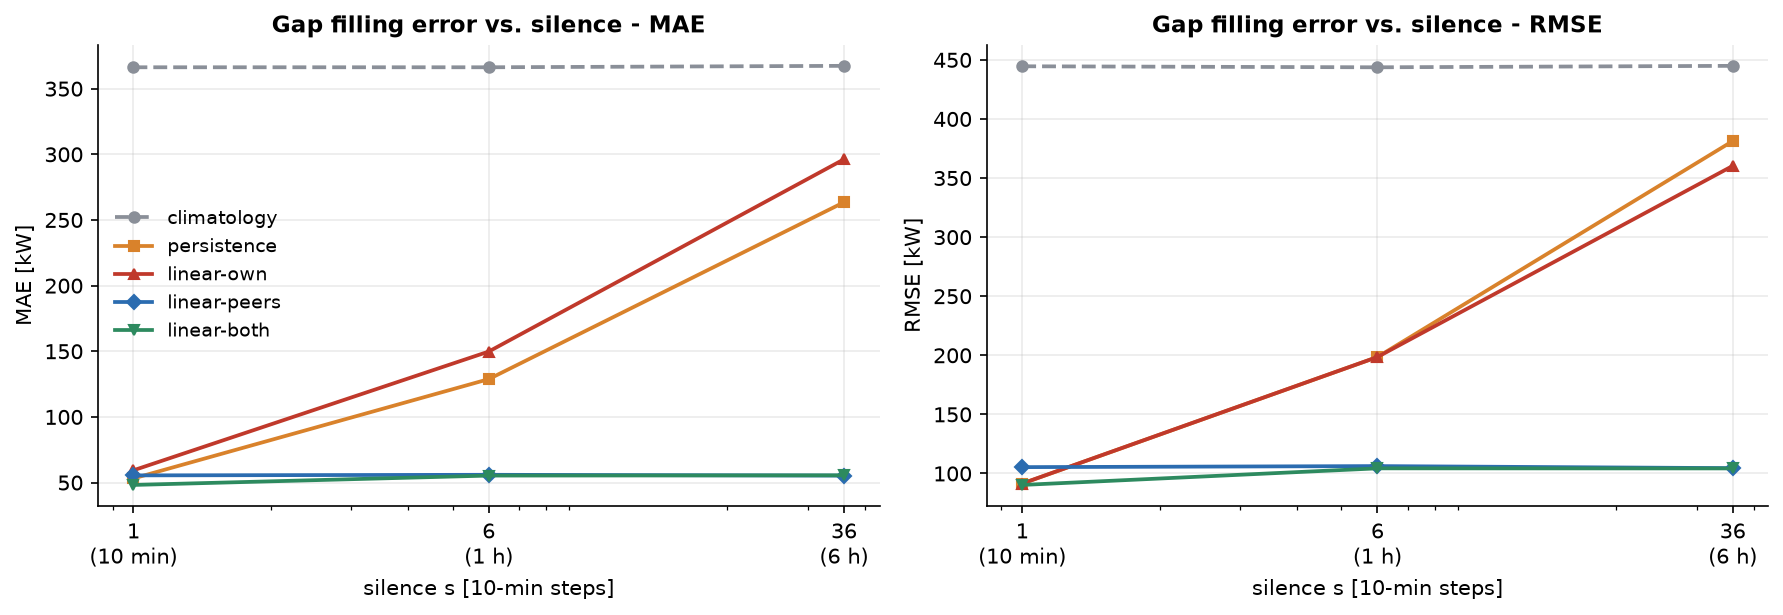

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.2))
styles = {
    "climatology":  dict(color="#8a8f98", marker="o", ls="--"),
    "persistence":  dict(color="#d9822b", marker="s"),
    "linear-own":   dict(color="#c0392b", marker="^"),
    "linear-peers": dict(color="#2b6cb0", marker="D"),
    "linear-both":  dict(color="#2d8a5f", marker="v"),
}
for ax, metric in zip(axes, ["MAE [kW]", "RMSE [kW]"]):
    for name in order:
        sub = res[res.model == name].sort_values("silence")
        ax.plot(sub.silence, sub[metric], label=name, lw=1.8, ms=5, **styles[name])
    ax.set_xscale("log")
    ax.set_xticks([1, 6, 36])
    ax.set_xticklabels(["1\n(10 min)", "6\n(1 h)", "36\n(6 h)"])
    ax.set_xlabel("silence s [10-min steps]")
    ax.set_ylabel(metric)
    ax.set_title(f"Gap filling error vs. silence - {metric.split()[0]}")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
print("saved:", C.save_figure(fig, "baselines_gapfill"))
plt.show()


## What the numbers say

1. **Spatial information beats temporal information as soon as the gap exceeds ten
   minutes.** `persistence` wins at `s = 1` and is beaten from `s = 6` onwards, while
   `linear-peers` is flat in `s` -- it reads the farm at step `t`, so it does not care how
   long the turbine has been silent. That crossover is the central mechanism behind the
   project's research question, and it is measurable with a plain ridge regression.

2. **The bar for the GNN is about 55 kW MAE, not the persistence floor.** Quoting the
   77.66 kW dataset-wide persistence number as the thing to beat would be too easy; on
   this episode set persistence is 53 kW at `s = 1` and `linear-peers` holds about 55 kW
   at every gap length.

3. **`linear-own` loses to `persistence` on MAE but not on RMSE.** It is fitted on squared
   error while being scored on absolute error, and the power distribution is heavily
   skewed (a mass at zero from shutdowns, a second mass near rated power). Which metric we
   report can flip a model ordering, so both are reported throughout.

4. **`linear-both` only beats `linear-peers` at `s = 1`**, where the 10-minute-old reading
   still carries information. By `s = 6` the two are within noise: the turbine's own
   history has stopped contributing and the farm is doing all the work.
